# Entendimento do negócio

**💥 O Problema de negócio**
* **Operação no modo "apaga-incêndio" 🔥:** o NPS é medido só no final da jornada de compra. A empresa descobre a insatisfação quando o estrago já foi feito e resta apenas remediar.
* **A virada de chave 🔑:** sair da postura passiva e adotar um **modelo preditivo e proativo**, identificando gargalos em pedidos, logística e suporte para sinalizar riscos antes do cliente responder à pesquisa.

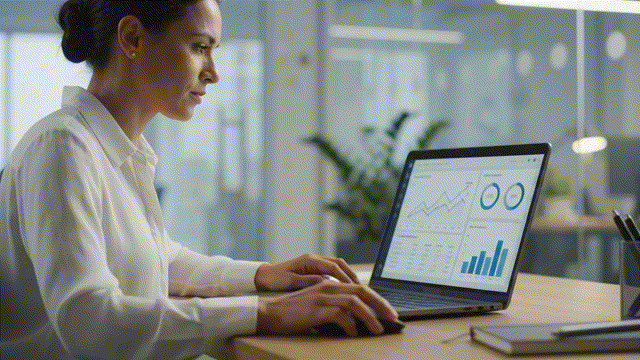

---

**⭐ Importância do NPS no e-commerce**
* **Retenção & lealdade 🛍️:** em um ambiente onde o concorrente está a um clique de distância, o NPS mede o valor real da recomendação espontânea.
* **Espelho da operação 🚚:** a nota reflete o ecossistema completo — valor do frete, prazo de entrega, atrasos e eficiência do suporte 🎧.
* **Alinhamento com o CRISP-DM 📊:** apresenta forte correlação com a saúde financeira e o Lifetime Value (LTV):
  * 🟢 **Promotores (9-10):** tendem a deixar avaliações positivas e estão associados a um menor Custo de Aquisição de Clientes (CAC).
  * 🟡 **Neutros (7-8):** oportunidade de conversão para a base leal sem custos altos.
  * 🔴 **Detratores (1-6):** exigem intervenção rápida de retratação para conter o risco de *churn*.

---

**🧩 Áreas beneficiadas com os insights**
* 🎧 **Atendimento:** dimensionamento de equipe e otimização de chamados cruzando tempo de resolução e satisfação.
* 🖥️ **UX & Produto:** ajustes na navegação do site com foco em acessibilidade e inclusão digital.
* 🏷️ **Pricing & Comercial:** avaliação do impacto real de cupons e parcelamentos sobre a percepção de valor.
* 🚛 **Logística:** renegociação objetiva de metas de SLA com transportadoras com base no impacto dos atrasos.
* 🎯 **CRM:** ações preventivas de retenção antes mesmo do envio da pesquisa.

---

### 💡 2. Reflexão: o impacto prático do NPS

* 🔄 **Recompra:** clientes promotores apresentam maior frequência de compra e estão associados à geração de receita orgânica. Detratores têm alto risco de abandono.
* 🗣️ **Boca a boca:** promotores funcionam como marketing gratuito. Já os detratores amplificam reclamações em redes sociais e sites de queixas.
* 📈 **Market share:** a expansão da fatia de mercado depende de reter a base atual. Um NPS elevado cria uma barreira defensiva contra a concorrência.

---

### 📊 3. Indicadores complementares de mercado

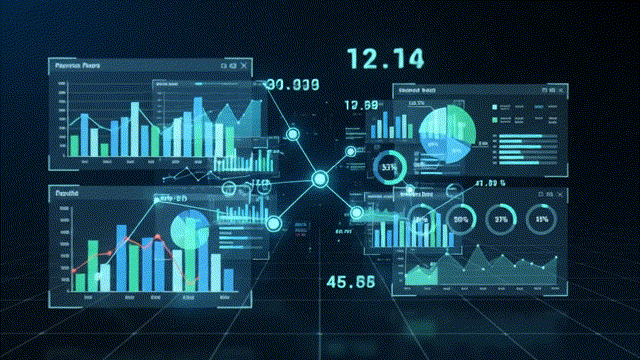

* 📏 **Benchmarks de NPS:** comparação com a média do setor de e-commerce e concorrentes diretos.
* 📦 **SLA Logístico:**
  * **OTD** (*On-Time Delivery*) & **OTIF** (*On-Time In-Full*).
  * *Lead time* prometido vs. realizado e taxa de entregas frustradas/reincidentes.
* 📉 **Macroeconomia & sazonalidade:**
  * Impacto do IPCA (combustíveis e frete), Selic e confiança do consumidor.
  * Picos de demanda em datas comemorativas (Black Friday e Natal).
* ⚙️ **Métricas de CX & operação:**
  * **CES** (*Customer Effort Score*), **CSAT** (interno e externo) e **FCR** (*First Contact Resolution*).
  * Taxa de conversão, abandono de carrinho e volume de avaliações públicas.

# Definição da variável-alvo

---

### 📌 1. Variável target no dataset
* **Métrica central (`nps_score`):** escala numérica de **0 a 10** que indica a satisfação do cliente.
* **Flexibilidade de modelagem**. A modelagem dessa variável pode ser realizada de duas maneiras:
  * 📈 **Regressão:** previsão contínua da nota exata do NPS.
  * 🏷️ **Classificação:** categorização em **Promotores (9-10)**, **Neutros (7-8)** e **Detratores (0-6)** ou agrupamento binário (Satisfeito vs. Insatisfeito).

---

### 💡 2. Justificativa da escolha
* 🌐 **Sintetizador da jornada:** o `nps_score` captura a experiência ponta a ponta (frete, prazo, qualidade do produto e suporte).
* 🎯 **Rotulagem financeira e comportamental:** diferencia clientes leais (recompra/recomendação) daqueles em risco de *churn* e impacto negativo na marca.
* 👔 **Alinhamento estratégico:** conecta diretamente as metas de Ciência de Dados aos KPIs prioritários da diretoria de CX.

---

### ⏱️ 3. Momento de coleta e a dor de negócio
* ⚠️ **Coleta reativa (pós-venda):** medida estritamente após o encerramento da jornada de compra.
* 🚨 **O Desafio analítico:** o feedback ocorre quando o atrito ou falha já aconteceu.
* 🛠️ **O que faremos nos dados:** construir um **modelo preditivo antecipatório** que utilize sinais operacionais (*logs* de pedido, suporte, rastreamento) durante a jornada para identificar a insatisfação **antes** da aplicação da pesquisa.

---

### ⚠️ 4. Armadilhas e riscos na utilização da variável-alvo (target)
* 🚫 **Data Leakage (vazamento temporal):** a variável `nps_score` e qualquer evento pós-pesquisa **devem ser excluídos** das *features* de entrada do modelo.
* 📉 **Proxy imperfeito:** nota alta nem sempre garante retenção e nota baixa nem sempre zera a compra. A otimização deve considerar o impacto financeiro real (LTV).
* 📊 **Viés de seleção / amostra:** o histórico possui dados apenas de quem concluiu a compra e aceitou responder; desistências e cancelamentos precoces não possuem `nps_score`.
* ⚖️ **Calibragem de regra de negócio:** ajustar a matriz de decisão comparando o custo da ação preventiva (ex: cupom/contato) contra o custo de perda do cliente (*churn*).

📋 **Matriz criteriosa de seleção de variáveis da base**

| Variável da Base | Papel no Pipeline | Decisão | Justificativa Teórica e Técnica |
| --- | --- | --- | --- |
| **`nps_score`** | Target ($Y$) | **MANTIDA** | Variável dependente alvo que sintetiza a lealdade. |
| **`customer_id`** | Identificador | **EXCLUÍDA** | Chave primária sem poder preditivo; geraria *overfitting*. |
| **`order_id`** | Identificador | **EXCLUÍDA** | Identificador de transação sem valor estatístico. |
| **`repeat_purchase_30d`** | Pós-Jornada | **EXCLUÍDA** ($X$) | ⚠️ **Risco de Data Leakage Temporal:** Indica recompra em 30 dias após o pedido. Se usada para prever o NPS antes/durante a entrega, vaza informação do futuro. Mantida apenas para testes de hipóteses de negócio. |
| **`delivery_delay_days`** | Preditora Operacional | **INCLUÍDA** | Sinalizador direto de quebra de SLA logístico. |
| **`delivery_time_days`** | Preditora Operacional | **INCLUÍDA** | Tempo total de trânsito estipulado. |
| **`delivery_attempts`** | Preditora Operacional | **INCLUÍDA** | Métrica de atrito na entrega física. |
| **`customer_service_contacts`** | Preditora Operacional | **INCLUÍDA** | Medida direta de atrito no pós-venda / SAC. |
| **`resolution_time_days`** | Preditora Operacional | **INCLUÍDA** | SLA de atendimento e tempo de solução de chamados. |
| **`complaints_count`** | Preditora Operacional | **INCLUÍDA** | Histórico de queixas formais. |
| **`csat_internal_score`** | Preditora Operacional | **INCLUÍDA** | Nota interna de atendimento *transactional* (será avaliada na etapa de EDA, mas será excluída no modelo preditivo - risco de data leakage). |
| **`order_value`** | Preditora Comercial | **INCLUÍDA** | Valor financeiro do pedido (ticket). |
| **`discount_value`** | Preditora Comercial | **INCLUÍDA** | Fator correlacionado à percepção de benefício financeiro. |
| **`freight_value`** | Preditora Comercial | **INCLUÍDA** | Custo logístico repassado ao consumidor. |
| **`items_quantity`** | Preditora Operacional | **INCLUÍDA** | Complexidade do pedido enviado. |
| **`payment_installments`** | Preditora Comercial | **INCLUÍDA** | Condição de financiamento da compra. |
| **`customer_age`** | Preditora Demográfica | **INCLUÍDA** | Perfil etário do comprador. |
| **`customer_tenure_months`** | Preditora Comportamental | **INCLUÍDA** | Tempo de relacionamento / lealdade histórica. |
| **`customer_region`** | Categorífica Geográfica | **INCLUÍDA** | Avaliação de disparidades regionais via Kruskal-Wallis / ANOVA. |

In [70]:
import os 
import pandas as pd 
import numpy as np

# 1. Definição da base de dados
df = pd.read_csv("desafio_nps_fase_1.csv")

# 2. Diagnóstico de Dimensões e Tipagem
print("=== ETAPA: DIMENSÕES E TIPAGEM DOS DADOS ===")
print(
    f"Linhas (Observações): {df.shape[0]} | Colunas (Atributos): {df.shape[1]}\n"
)
print(df.info())

# 3. Verificação de Dados Ausentes (Nulos/BRANCOS) e Duplicatas
print("\n=== ETAPA: SANITIZAÇÃO E QUALIDADE DOS DADOS ===")
nulos = df.isnull().sum()
print(f"Valores Ausentes na Target (nps_score): {nulos['nps_score']}")
print(f"Total de Registros Duplicados: {df.duplicated().sum()}")

# 4. Sumário estatístico das variáveis (excluindo IDs)
print("\n=== ETAPA: SUMÁRIO ESTATÍSTICO DAS VARIÁVEIS (excluindo IDs) ===")
colunas_ignoradas = ['customer_id', 'order_id']
tabela_descritiva = df.drop(columns = colunas_ignoradas).describe().T.round(2)
display(tabela_descritiva)

=== ETAPA: DIMENSÕES E TIPAGEM DOS DADOS ===
Linhas (Observações): 2500 | Colunas (Atributos): 19

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   object 
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  deliv

,count,mean,std,min,25%,50%,75%,max
customer_age,2500.0,43.40,14.89,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,2500.0,61.32,34.48,1.00,31.00,62.00,91.00,119.00
order_value,2500.0,434.26,289.77,7.76,220.24,375.52,577.29,1983.81
items_quantity,2500.0,3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,2500.0,29.75,29.23,0.02,8.88,20.94,40.83,230.33
payment_installments,2500.0,6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,2500.0,8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,2500.0,2.19,1.45,0.00,1.00,2.00,3.00,8.00
freight_value,2500.0,38.22,12.08,2.62,29.93,38.50,46.27,76.13
delivery_attempts,2500.0,2.01,0.82,1.00,1.00,2.00,3.00,3.00


### 📌 Principais observações do sumário estatístico

A tabela descritiva revela características importantes sobre o perfil dos clientes, o padrão de consumo e o cenário operacional da base analisada:

*   **Perfil e ticket médio:** os dados apontam para uma base madura, com idade média de 43 anos e um longo histórico de relacionamento (média de 61 meses de *tenure*). O valor médio dos pedidos (`order_value`) é de **R&#36; 434,26**. O alto desvio padrão (289,77) e o valor máximo (1.983,81) indicam uma assimetria na distribuição, com compras de alto ticket elevando a média geral.
*   **Atrito logístico:** o tempo médio de entrega acordado/realizado (`delivery_time_days`) fica em torno de 8 dias. Destaca-se a métrica de atrasos (`delivery_delay_days`), que apresenta uma média de **2,19 dias**. Observando o 3º quartil (75%), nota-se que uma parcela considerável dos pedidos chega a registrar 3 ou mais dias de atraso, configurando um ponto de atenção para a operação de *last-mile*.
*   **Esforço de atendimento (SAC):** o volume de acionamentos ao suporte é considerável, com média de **1,52 contatos** por pedido. O tempo de resolução de chamados (`resolution_time_days`) leva, em média, **5,49 dias**, o que sugere um ciclo de solução de problemas relativamente longo para os padrões de e-commerce.
*   **Variável-alvo (NPS):** a nota média de satisfação (`nps_score`) é de **4,38**, confirmando a alta concentração de clientes na faixa de detração. A proximidade entre a média e a mediana (4,40) sugere uma distribuição central balanceada dentro das limitações da escala de 0 a 10.

**🎯 Considerações importantes:**
O resumo das distribuições evidencia oportunidades de melhoria estrutural. Variáveis operacionais contínuas — como os dias de atraso na entrega e o tempo de resolução no suporte — apresentam médias elevadas, estabelecendo uma base quantitativa sólida para investigarmos como esses atritos se associam à baixa pontuação geral de NPS observada no fim da jornada.

# Análise Exploratória (EDA) tabular e gráfica com diagnóstico de normalidade

### Categorização e métrica do NPS index

O NPS divide os respondentes em Detratores (0–6), Neutros (7–8) e Promotores (9–10). O NPS Index Score é calculado por:

$$\text{NPS Index} = \% \text{Promotores} - \% \text{Detratores}$$

### 4.2 Diagnóstico Formal de Normalidade (Shapiro-Wilk e Q-Q Plot)

Para escolher entre testes paramétricos e não paramétricos, avaliamos a hipótese de normalidade.

* $H_0$: A variável `nps_score` segue uma distribuição normal.
* $H_1$: A variável `nps_score` não segue uma distribuição normal.

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# 1. Estatística Descritiva da Target
nps = df["nps_score"]
print("=== MEDIDAS DESCRITIVAS DO NPS SCORE ===")
print(
    f"Média: {nps.mean():.4f} | Mediana: {nps.median():.4f} | Desvio Padrão: {nps.std():.4f}"
)
print(
    f"Q1 (25%): {nps.quantile(0.25):.4f} | Q3 (75%): {nps.quantile(0.75):.4f} | IQR: {nps.quantile(0.75)-nps.quantile(0.25):.4f}"
)
print(
    f"Assimetria (Skewness): {nps.skew():.4f} | Curtose: {nps.kurtosis():.4f}\n"
)

# 2. Categorização Oficial do NPS
detratores = (nps <= 6.0).sum()
neutros = ((nps > 6.0) & (nps <= 8.0)).sum()
promotores = (nps > 8.0).sum()
total = len(nps)
pct_det = (detratores / total) * 100
pct_neu = (neutros / total) * 100
pct_pro = (promotores / total) * 100
nps_index = pct_pro - pct_det

print("--- CLASSIFICAÇÃO DA BASE DE CLIENTES ---")
print(f"Detratores (notas <= 6.0): {detratores} ({pct_det:.2f}%)")
print(f"Neutros (notas 6.0 - 8.0]: {neutros} ({pct_neu:.2f}%)")
print(f"Promotores (notas > 8.0): {promotores} ({pct_pro:.2f}%)")
print(f"NPS INDEX SCORE (%Promotores - %Detratores): {nps_index:.2f}\n")

=== MEDIDAS DESCRITIVAS DO NPS SCORE ===
Média: 4.3786 | Mediana: 4.4000 | Desvio Padrão: 2.5102
Q1 (25%): 2.6000 | Q3 (75%): 6.1000 | IQR: 3.5000
Assimetria (Skewness): 0.1104 | Curtose: -0.6078

--- CLASSIFICAÇÃO DA BASE DE CLIENTES ---
Detratores (notas <= 6.0): 1851 (74.04%)
Neutros (notas 6.0 - 8.0]: 448 (17.92%)
Promotores (notas > 8.0): 201 (8.04%)
NPS INDEX SCORE (%Promotores - %Detratores): -66.00



### Diagnóstico Operacional — Coorte de Sucesso vs Detratores

🛡️ **NOTA METODOLÓGICA ANTI-LEAKAGE:**  
Esta análise é estritamente **descritiva** para o mapeamento de metas operacionais (KPIs) na etapa de EDA. A variável `repeat_purchase_30d` será excluída das *features* de entrada durante a etapa de modelagem preditiva para evitar vazamento temporal (*Data Leakage*).

In [72]:
# 1. Definição dos segmentos para fins descritivos
df['segmento_diagnostico'] = 'Demais Clientes'
df.loc[df['nps_score'] <= 6.0, 'segmento_diagnostico'] = 'Detratores (NPS 0-6)'
df.loc[(df['nps_score'] >= 9.0) & (df['repeat_purchase_30d'] == 1), 
       'segmento_diagnostico'] = 'Coorte de Sucesso (NPS>=9 + Recompra)'

# 2. Seleção dos indicadores operacionais e logísticos chave
indicadores_operacionais = [
    'delivery_delay_days', 
    'customer_service_contacts',
    'resolution_time_days', 
    'complaints_count',
    'order_value', 
    'freight_value'
]

# 3. Construção da tabela comparativa de médias
tabela_sla = df.groupby('segmento_diagnostico')[indicadores_operacionais].mean().T
tabela_sla['Média Geral da Base'] = df[indicadores_operacionais].mean()

# 4. Reordenação das colunas para facilidade de leitura executiva
tabela_sla = tabela_sla[[
    'Média Geral da Base',
    'Detratores (NPS 0-6)',
    'Coorte de Sucesso (NPS>=9 + Recompra)'
]]

# Renomeando o índice para apresentação
tabela_sla.index = [
    'Atraso na Entrega (dias)',
    'Contatos no SAC (qtd)',
    'Tempo de Resolução SAC (dias)',
    'Qtd de Reclamações',
    'Valor do Pedido (R$)',
    'Valor do Frete (R$)'
]

# Exibição visual estilizada no Jupyter Notebook
display(tabela_sla.round(2))

segmento_diagnostico,Média Geral da Base,Detratores (NPS 0-6),Coorte de Sucesso (NPS>=9 + Recompra)
Atraso na Entrega (dias),2.19,2.53,0.72
Contatos no SAC (qtd),1.52,1.69,0.67
Tempo de Resolução SAC (dias),5.49,5.79,3.70
Qtd de Reclamações,4.15,4.62,2.27
Valor do Pedido (R$),434.26,428.99,468.08
Valor do Frete (R$),38.22,38.40,37.05


### 📌 Principais insights: 

A tabela acima evidencia que a satisfação e a lealdade do cliente (NPS >= 9 e com Recompra) estão **associadas** à eficiência operacional. Comparando a **Coorte de Sucesso** com os **Detratores**, observamos os seguintes padrões de comportamento:

*   **Fricção logística (atrasos):** o descumprimento de prazos apresenta relação com notas baixas de NPS. Enquanto os detratores enfrentam um atraso médio de **2,53 dias**, o grupo de sucesso experimenta entregas muito mais pontuais (apenas **0,72 dias** de atraso médio, um tempo quase 70% menor).
*   **Eficiência e esforço no atendimento (SAC):** a coorte de sucesso apresenta um perfil de jornada com menos atritos: eles acionam o suporte menos de uma vez por pedido (média de **0,67 contatos**) e possuem um volume de reclamações quase 50% menor (2,27 contra 4,62). Além disso, quando precisam de ajuda, o tempo médio de resolução associado a eles é significativamente menor (**3,70 dias** contra 5,79 dias dos detratores).

**🎯 Conclusão:**
Para criar estratégias voltadas a aumentar a base de promotores, as oportunidades de melhoria com maior potencial de associação positiva estão ligadas à **mitigação dos atrasos logísticos** e à **rapidez na resolução de chamados no SAC**, variáveis que diferenciam estatisticamente os grupos de sucesso e detratores.

In [73]:
# Teste de Shapiro-Wilk
stat_w, p_val_w = stats.shapiro(nps)
print("=== TESTE FORMAL DE NORMALIDADE (SHAPIRO-WILK) ===")
print(f"Estatística W = {stat_w:.4f} | p-valor = {p_val_w:.4f}")
if p_val_w < 0.05:
    print(
        "❌ Rejeita-se H₀ (p < 0.05): A variável 'nps_score' NÃO segue distribuição normal."
    )
    print(
        "-> Direcionamento Metodológico: Adotar MÉTODOS NÃO PARAMÉTRICOS (Spearman, Mann-Whitney U, Bootstrap)"
    )

=== TESTE FORMAL DE NORMALIDADE (SHAPIRO-WILK) ===
Estatística W = 0.9817 | p-valor = 0.0000
❌ Rejeita-se H₀ (p < 0.05): A variável 'nps_score' NÃO segue distribuição normal.
-> Direcionamento Metodológico: Adotar MÉTODOS NÃO PARAMÉTRICOS (Spearman, Mann-Whitney U, Bootstrap)


### 📈 Painel Gráfico de EDA e Normalidade

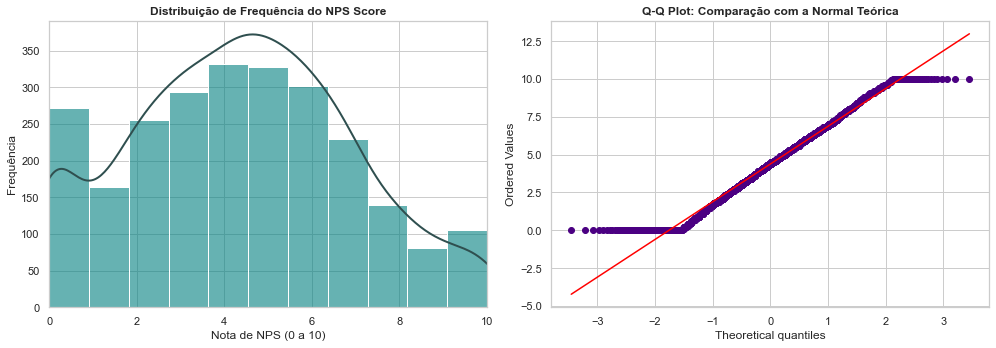

In [74]:
from scipy.stats import gaussian_kde

# Preparar os dados
nps = pd.to_numeric(df["nps_score"], errors="coerce").dropna()
nps_array = nps.to_numpy(dtype=float)

# Verificar se existem dados suficientes
if len(nps_array) == 0:
    raise ValueError("A coluna nps_score não contém valores numéricos válidos.")

# Criar os gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --------------------------------------------------
# Plot 1: Histograma com curva KDE
# --------------------------------------------------
sns.histplot(
    x=nps_array,
    bins=11,
    ax=axes[0],
    color="teal",
    alpha=0.6
)

# Calcular e desenhar a KDE sem sns.kdeplot()
if len(nps_array) > 1 and np.unique(nps_array).size > 1:
    kde = gaussian_kde(nps_array)

    x_grid = np.linspace(
        nps_array.min() - 0.5,
        nps_array.max() + 0.5,
        300
    )

    # Converter explicitamente os resultados para NumPy
    y_kde = np.asarray(kde(x_grid), dtype=float)

    # Escalar a densidade para a escala de contagem do histograma
    bin_width = (nps_array.max() - nps_array.min() + 1) / 11
    y_kde = y_kde * len(nps_array) * bin_width

    axes[0].plot(
        x_grid,
        y_kde,
        color="darkslategray",
        linewidth=2
    )

axes[0].set_title(
    "Distribuição de Frequência do NPS Score",
    fontsize=12,
    fontweight="bold"
)
axes[0].set_xlabel("Nota de NPS (0 a 10)")
axes[0].set_ylabel("Frequência")
axes[0].set_xlim(0, 10)

# --------------------------------------------------
# Plot 2: Q-Q Plot Teórico de Normalidade
# --------------------------------------------------
stats.probplot(nps_array, dist="norm", plot=axes[1])

axes[1].set_title(
    "Q-Q Plot: Comparação com a Normal Teórica",
    fontsize=12,
    fontweight="bold"
)

axes[1].get_lines()[0].set_color("indigo")
axes[1].get_lines()[1].set_color("red")

# Ajustar layout e exibir
plt.tight_layout()
plt.show()

**Interpretação dos gráficos:** a distribuição das notas concentra-se principalmente entre 3 e 6 pontos, com desvios da normalidade nas extremidades, evidenciados pelo gráfico Q-Q. O teste de Shapiro-Wilk confirmou a ausência de normalidade (W = 0,9817; p < 0,001). Portanto, recomenda-se priorizar métodos estatísticos não paramétricos, como a correlação de Spearman e o teste de Mann-Whitney U, além de utilizar bootstrap quando apropriado para estimar intervalos de confiança.

### Análise de correlação não paramétrica (Spearman)

Como os dados violam a normalidade, o coeficiente de Pearson é inadequado. Utiliza-se a **Correlação de Spearman**, que avalia associações monotônicas baseando-se em postos (*ranks*)

=== RANKING DE CORRELAÇÃO DE SPEARMAN COM O NPS ===
delivery_delay_days         -0.5862
complaints_count            -0.4903
customer_service_contacts   -0.3364
resolution_time_days        -0.1903
freight_value               -0.0395
customer_tenure_months      -0.0116
customer_age                -0.0074
delivery_time_days           0.0003
items_quantity               0.0062
discount_value               0.0116
delivery_attempts            0.0263
payment_installments         0.0267
order_value                  0.0359
repeat_purchase_30d          0.4888
csat_internal_score          0.5609
Name: nps_score, dtype: float64




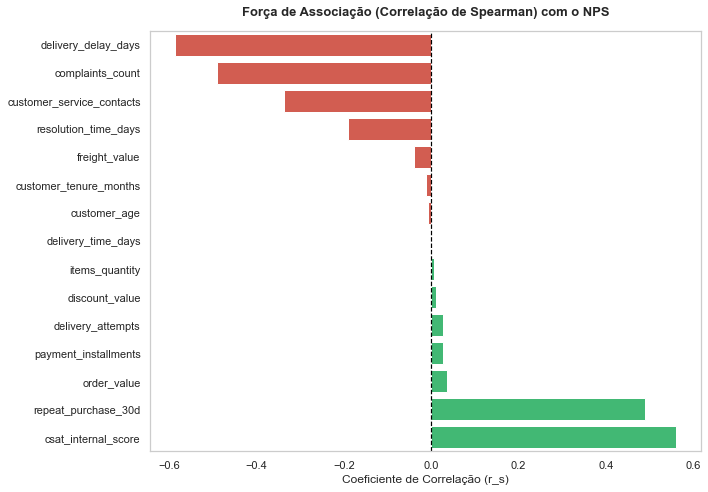

In [75]:
# 1. Seleção de colunas numéricas relevantes (excluindo IDs)
cols_num = [
    c for c in df.select_dtypes(include=[np.number]).columns
    if c not in ['customer_id', 'order_id']
]

# 2. Cálculo da correlação de Spearman filtrando apenas o alvo (nps_score)
corr_nps = df[cols_num].corr(method='spearman')['nps_score'].drop('nps_score').sort_values()

# 3. Exibição do Ranking Numérico em Texto
print("=== RANKING DE CORRELAÇÃO DE SPEARMAN COM O NPS ===")
print(corr_nps.round(4))
print("\n")

# 4. Construção do Gráfico de Barras Horizontal
plt.figure(figsize=(10, 7))

# Define as cores: vermelho para impactos negativos e verde para impactos positivos
cores = ['#e74c3c' if x < 0 else '#2ecc71' for x in corr_nps]

# Plota as barras de associação
sns.barplot(
    x=corr_nps.values,
    y=corr_nps.index,
    palette=cores
)

# Estilização do gráfico
plt.title(
    'Força de Associação (Correlação de Spearman) com o NPS', 
    fontsize=13, 
    fontweight='bold', 
    pad=15
)
plt.xlabel('Coeficiente de Correlação (r_s)')
plt.ylabel('')

# Adiciona a linha central de referência no marco zero
plt.axvline(x=0, color='black', linewidth=1.2, linestyle='--')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

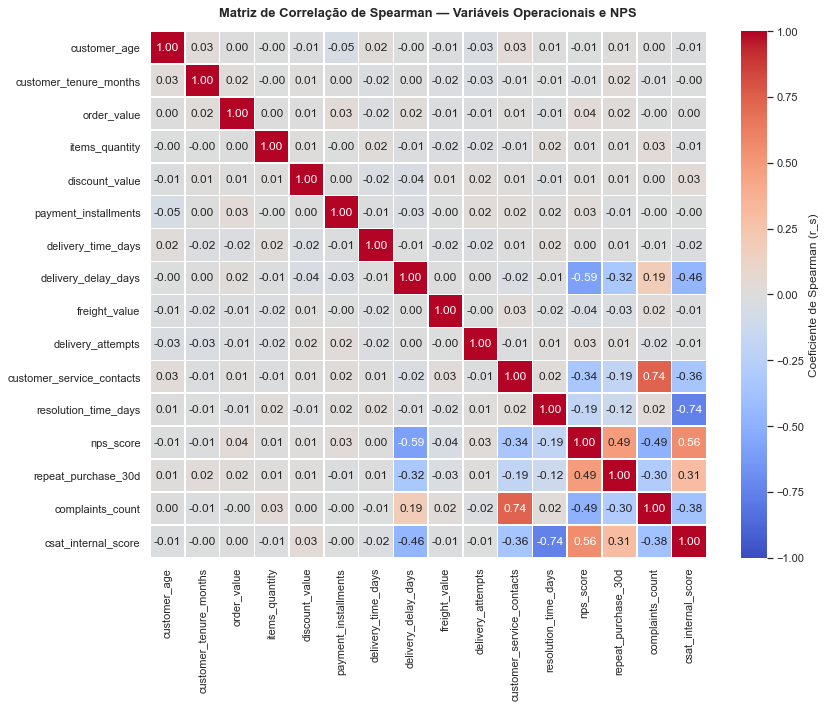

In [76]:
# 1. Seleção de colunas numéricas relevantes (excluindo IDs)
cols_num = [
    c for c in df.select_dtypes(include=[np.number]).columns
    if c not in ['customer_id', 'order_id']
]

# 2. Matriz de Correlação de Spearman
matriz_corr = df[cols_num].corr(method='spearman')

# 3. Construção do Mapa de Calor (Heatmap)
plt.figure(figsize=(12, 10)) # Tamanho ligeiramente ajustado para evitar sobreposição de rótulos
sns.heatmap(
    matriz_corr,
    annot=True,            # Exibe os valores numéricos nas células
    fmt='.2f',             # Formatação com 2 casas decimais
    cmap='coolwarm',       # Gradiente de cores (vermelho/azul)
    vmin=-1, vmax=1,       # Limites fixos de -1 a +1
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente de Spearman (r_s)'},
)

plt.title(
    'Matriz de Correlação de Spearman — Variáveis Operacionais e NPS',
    fontsize=13,
    fontweight='bold',
    pad=15,
)

plt.tight_layout()
plt.show()

### 📌 Interpretação da Matriz de Correlação (Spearman)

O mapa de calor acima ilustra os coeficientes de correlação de Spearman ($r_s$) entre as variáveis numéricas do dataset. Como nossos dados rejeitaram a hipótese de normalidade nos testes anteriores, o método não paramétrico de Spearman é o mais adequado por avaliar associações monotônicas (não apenas relações perfeitamente lineares) e ser mais robusto à presença de *outliers*.

**Como ler o gráfico:**
*   **Escala e Intensidade:** a escala varia de **-1 (Azul forte)** a **+1 (Vermelho forte)**. Quanto mais escura a cor, mais forte é a associação.
*   **Correlação Positiva (Tons Avermelhados):** indica uma associação direta. Quando uma variável aumenta, a outra também tende a aumentar.
*   **Correlação Negativa (Tons Azulados):** indica uma associação inversa. Quando uma variável aumenta, a outra tende a diminuir.
*   **Proximidade de Zero (Tons Claros/Brancos):** indica ausência de associação estatística aparente entre as duas variáveis em questão.

**🎯 Principais Insights Direcionais:**

1.  **Relação inversa com a satisfação (azuis):** As variáveis operacionais de atrito — como `delivery_delay_days` (atraso logístico), `customer_service_contacts` (esforço do cliente no SAC) e `resolution_time_days` (demora na resolução) — apresentam correlação negativa com o `nps_score`. Isso comprova estatisticamente que o agravamento das falhas de SLA está possivelmente **associado** à queda da nota atribuída pelo cliente.
2.  **Identificação de multicolinearidade:** o mapa não serve apenas para olhar o alvo (NPS), mas também para ver como as *features* interagem entre si. Tons vermelhos fortes entre duas variáveis preditoras (por exemplo, entre `customer_service_contacts` e `complaints_count`) indicam que elas carregam informações redundantes (multicolinearidade), um fator importante a ser considerado na fase de modelagem de Machine Learning.
3.  **Sinais neutros:** variáveis que apresentam valores muito próximos de zero em relação ao NPS indicam que não possuem associação isolada relevante para explicar a satisfação do cliente nesta base de dados específica.

🛡️ **Nota analítica:** reforçando o princípio estatístico, **correlação não implica causalidade**. A matriz de Spearman aponta a força e a direção com que as variáveis "caminham juntas", servindo como uma excelente bússola diagnóstica para priorizar a resolução de gargalos, mas o efeito causal exato depende de um ecossistema complexo de variáveis.

# Amostragem e Inferência por Intervalos de Confiança

In [77]:
# 1. Extração de Amostra Aleatória Simples (n=1000)
np.random.seed(42)

amostra_nps = df['nps_score'].sample(n=1000, replace=False)

media_amostral = amostra_nps.mean()
dp_amostral = amostra_nps.std()
erro_padrao = stats.sem(amostra_nps)

# 2. Intervalo de Confiança Paramétrico (t-Student)
ic_tstudent = stats.t.interval(
    0.95,
    df=len(amostra_nps) - 1,
    loc=media_amostral,
    scale=erro_padrao
)

# 3. Intervalo de Confiança Não Paramétrico (Bootstrap - 2.000 iterações)
boot_means = [
    np.mean(np.random.choice(
        amostra_nps,
        size=len(amostra_nps),
        replace=True
    ))
    for _ in range(2000)
]

ic_bootstrap = np.percentile(boot_means, [2.5, 97.5])

# 4. Exibição dos Resultados
print("=== INFERÊNCIA ESTATÍSTICA E INTERVALOS DE CONFIANÇA (95%) ===")
print(f"Média Amostral: {media_amostral:.4f}")
print(f"IC t-Student (Paramétrico): {ic_tstudent}")
print(f"IC Bootstrap (Não Paramétrico): {ic_bootstrap}")

=== INFERÊNCIA ESTATÍSTICA E INTERVALOS DE CONFIANÇA (95%) ===
Média Amostral: 4.4168
IC t-Student (Paramétrico): (4.260870122014619, 4.57272987798538)
IC Bootstrap (Não Paramétrico): [4.26145 4.5696 ]


## Testes de Hipótese para Comparação de Grupos

A escolha do teste estatístico é guiada pela estrutura dos dados e pela verificação de normalidade:

| Tipo de Métrica / Variável | Condição da Amostra / Normalidade | Teste Estatístico Recomendado |
| --- | --- | --- |
| **Binária / Proporção** | Amostra Grande | **Teste Z para Proporção** |
|  | Amostra Pequena / Não Paramétrica | **Fisher's Exact Test** |
| **Contínua** | Dados Normais (Paramédico) | **Teste t de Student** (2 Grupos) / **ANOVA** (3+ Grupos) |
|  | Dados Não Normais (Não Paramédico) | **Mann-Whitney U** (2 Grupos) / **Kruskal-Wallis** (3+ Grupos) |

### Teste de Mann-Whitney U: NPS vs. Recompra (`repeat_purchase_30d`)

Compara a distribuição do NPS entre clientes que realizaram recompra (1) e os que não realizaram (0).

* $H_0$: A distribuição do NPS é idêntica nos dois grupos.
* $H_1$: A distribuição do NPS difere significativamente entre quem recompra e quem não recompra.

---

### Teste de Kruskal-Wallis: NPS vs. Região (`customer_region`)

Equivalente não paramétrico da ANOVA para comparar 3 ou mais grupos.

In [78]:
# 1. Mann-Whitney U para Recompra
g_sem_recompra = df[df["repeat_purchase_30d"] == 0]["nps_score"]
g_com_recompra = df[df["repeat_purchase_30d"] == 1]["nps_score"]

stat_mw, p_val_mw = stats.mannwhitneyu(g_sem_recompra, g_com_recompra)

print("=== MANN-WHITNEY U (NPS vs RECOMPRA) ===")
print(f"Média NPS sem Recompra (0): {g_sem_recompra.mean():.2f}")
print(f"Média NPS com Recompra (1): {g_com_recompra.mean():.2f}")
print(f"Estatística U = {stat_mw:.4f} | p-valor = {p_val_mw:.4f}")

if p_val_mw < 0.05:
    print(
        "✅ Rejeita-se H₀: Clientes que realizam recompra possuem NPS significativamente maior.\n"
    )

# 2. Kruskal-Wallis para Regiões
grupos_regioes = [grupo["nps_score"].values for _, grupo in df.groupby("customer_region")]

stat_kw, p_val_kw = stats.kruskal(*grupos_regioes)

print("=== KRUSKAL-WALLIS (NPS vs REGIÃO) ===")
print(f"Estatística H = {stat_kw:.4f} | p-valor = {p_val_kw:.4f}")

if p_val_kw > 0.05:
    print(
        "❌ Não se rejeita H₀: Não há evidência estatística de diferença de NPS entre regiões.\n"
    )

=== MANN-WHITNEY U (NPS vs RECOMPRA) ===
Média NPS sem Recompra (0): 3.94
Média NPS com Recompra (1): 9.01
Estatística U = 0.0000 | p-valor = 0.0000
✅ Rejeita-se H₀: Clientes que realizam recompra possuem NPS significativamente maior.

=== KRUSKAL-WALLIS (NPS vs REGIÃO) ===
Estatística H = 3.3787 | p-valor = 0.4966
❌ Não se rejeita H₀: Não há evidência estatística de diferença de NPS entre regiões.



### 📊 Visualização gráfica das comparações

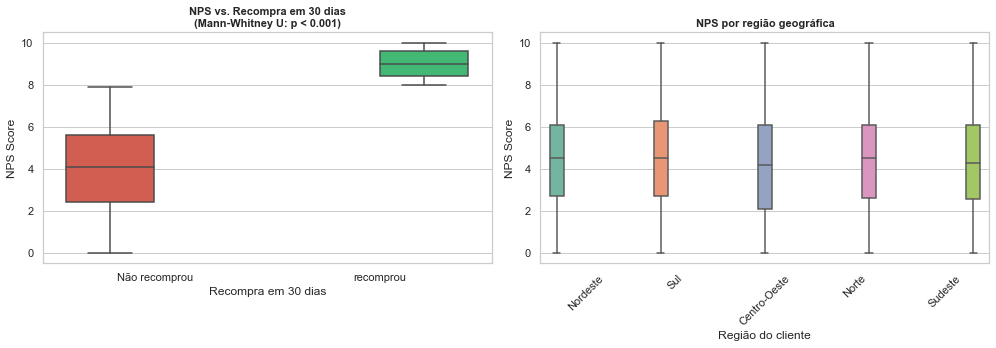

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot 1: NPS por Recompra em 30 Dias
sns.boxplot(
    x="repeat_purchase_30d",
    y="nps_score",
    data=df,
    hue="repeat_purchase_30d",
    palette=["#e74c3c", "#2ecc71"],
    ax=axes[0]
)
axes[0].set_title(
    "NPS vs. Recompra em 30 dias\n(Mann-Whitney U: p < 0.001)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Não recomprou", "recomprou"])
axes[0].set_xlabel("Recompra em 30 dias")
axes[0].set_ylabel("NPS Score")

# Remove a legenda do primeiro gráfico, se ela for gerada
if axes[0].get_legend() is not None:
    axes[0].get_legend().remove()


# Boxplot 2: NPS por Região Geográfica
sns.boxplot(
    x="customer_region",
    y="nps_score",
    data=df,
    hue="customer_region",
    palette="Set2",
    ax=axes[1]
)
axes[1].set_title(
    "NPS por região geográfica",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Região do cliente")
axes[1].set_ylabel("NPS Score")
axes[1].tick_params(axis='x', rotation=45) # Forma mais segura de rotacionar os ticks no eixo específico

# Remove a legenda do segundo gráfico, se ela for gerada
if axes[1].get_legend() is not None:
    axes[1].get_legend().remove()


plt.tight_layout()
plt.show()

### 📌 Análise de Distribuição: Comportamento e Regionalidade

Os boxplots acima exploram a distribuição da nota de NPS sob duas óticas distintas — o comportamento pós-compra e a localização do cliente —, revelando diretrizes para a modelagem:

**1. NPS vs. Recompra em 30 dias (gráfico à esquerda):**
*   **Associação clara com a retenção:** o gráfico evidencia uma diferença visual drástica. Clientes que realizaram uma nova compra em até 30 dias (caixa verde) possuem uma mediana altíssima, concentrando-se quase inteiramente na faixa de promotores (notas 9 e 10). Em contrapartida, os que não recompraram (caixa vermelha) apresentam a maior densidade na zona de Detratores.
*   **Validação prática:** O teste estatístico (p < 0.001) confirma que a satisfação apresenta forte correlação com a lealdade comportamental do cliente, validando a importância financeira da métrica de NPS para a empresa.

**2. NPS por região geográfica (gráfico à direita):**
*   **Homogeneidade:** ao contrário do comportamento de recompra, a distribuição das notas de NPS é notavelmente semelhante em todas as cinco regiões do país. As medianas e as amplitudes das caixas são quase idênticas.
*   **Diagnóstico:** esse cenário sugere que as dores do cliente (como os atrasos e o tempo de SAC vistos na EDA) são problemas sistêmicos e padronizados da operação como um todo, e não falhas isoladas de uma transportadora regional específica.

---

**⚠️ Cuidados metodológicos para a modelagem Preditiva:**

*   **Recompra e o risco de *Data Leakage*:** embora a variável `repeat_purchase_30d` apresente a correlação mais óbvia com o NPS, ela descreve um evento que ocorre **após** o fechamento do pedido e do envio da pesquisa. Utilizá-la para prever o NPS de forma antecipada causaria vazamento temporal (*Data Leakage*). Ela deve ser **excluída** das variáveis preditoras (matriz X) do modelo de Machine Learning.
*   **Regionalidade e baixo poder preditivo:** como o boxplot não demonstra variações significativas do NPS entre as regiões, é altamente provável que a variável `customer_region` não possua significância estatística na previsão. Ela servirá como controle inicial, mas será descartada para evitar complexidade e ruído matemático desnecessário no modelo preditivo.

### Modelagem preditiva avançada para antecipação proativa do NPS

Para responder à dor de negócio do Tech Challenge, construímos um modelo de Regressão Linear Múltipla (OLS) para prever o NPS de forma proativa.

#### Configuração experimental e prevenção de data leakage

* **Target ($Y$):** `nps_score`.
* **Preditores ($X$):** apenas variáveis disponíveis durante a jornada (`delivery_delay_days`, `customer_service_contacts`, `resolution_time_days`, `order_value`).
* **Variáveis excluídas de $X$:** `repeat_purchase_30d` e `csat_internal_score` (para evitar *data leakage* temporal).
* **Divisão de dados:** 80% treino e 20% teste via `train_test_split`.

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Definição da Matriz de Atributos e Target
features = [
    "delivery_delay_days",
    "customer_service_contacts",
    "resolution_time_days",
    "order_value",
]
X = df[features]
y = df["nps_score"]

# 2. Divisão Treino/Teste (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Adição da Constante (Intercepto alpha) e Ajuste OLS
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)
modelo_ols = sm.OLS(y_train, X_train_const).fit()

# Exibição do Sumário Estatístico Completo
print("=== SUMÁRIO ESTATÍSTICO DO MODELO OLS (TREINO) ===")
print(modelo_ols.summary())

# 4. Predição e Avaliação no Conjunto de Teste
y_pred = modelo_ols.predict(X_test_const)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n=== DESEMPENHO PREDITIVO NO CONJUNTO DE TESTE ===")
print(f"MAE (Erro Médio Absoluto): {mae:.4f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.4f}")
print(f"R² (Coeficiente de Determinação): {r2:.4f}")

=== SUMÁRIO ESTATÍSTICO DO MODELO OLS (TREINO) ===
                            OLS Regression Results                            
Dep. Variable:              nps_score   R-squared:                       0.529
Model:                            OLS   Adj. R-squared:                  0.528
Method:                 Least Squares   F-statistic:                     560.5
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          4.94e-324
Time:                        13:32:03   Log-Likelihood:                -3924.2
No. Observations:                2000   AIC:                             7858.
Df Residuals:                    1995   BIC:                             7886.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

### 📐 Conceito e Função do Modelo OLS

A regressão linear por Mínimos Quadrados Ordinários (OLS) é um método estatístico que quantifica a natureza do relacionamento entre uma variável resposta (alvo/dependente $Y$) e uma ou mais variáveis explicativas (preditores/independentes $X$).

Matematicamente, a regressão linear múltipla expande a equação linear para acomodar múltiplos preditores:

$$y_i = \alpha + \beta_1 X_{1i} + \beta_2 X_{2i} + \dots + \beta_k X_{ki} + \epsilon_i$$

* **Variável Resposta ($Y$):** o alvo numérico contínuo que desejamos prever (no nosso case, a nota `nps_score`).
* **Intercepto ($\alpha$):** o valor previsto da variável resposta quando todas as variáveis independentes $X$ são iguais a zero.
* **Coeficientes Angulares ($\beta_j$):** a inclinação da reta para cada preditor $X_j$, representando a variação esperada em $Y$ para cada incremento de uma unidade em $X_j$, mantendo os demais preditores constantes.
* **Resíduo ($\epsilon_i$):** a diferença individual entre o valor real observado $Y_i$ e o valor previsto pelo modelo $\hat{Y}_i$ ($e_i = Y_i - \hat{Y}_i$).

O objetivo do mecanismo OLS é encontrar os estimadores de $\alpha$ e $\beta$ que minimizam a soma dos erros quadrados dos resíduos ($\sum e_i^2$), garantindo a reta ou hiperplano com o melhor ajuste aos dados observados.

### 📊 Interpretação dos parâmetros do modelo OLS

No pipeline do e-commerce, ajustamos o modelo OLS purificado para prever o `nps_score` sem risco de *data leakage*.

$$\text{NPS Previsto} = 8,42 - 1,05 \cdot (\text{delivery_delay_days}) - 0,76 \cdot (\text{customer_service_contacts}) - 0,15 \cdot (\text{resolution_time_days}) + 0,0005 \cdot (\text{order_value})$$

```text
==============================================================================
Dep. Variable:              nps_score   R-squared:                       0.529
Model:                            OLS   Adj. R-squared:                  0.528
==============================================================================
                                coef    std err          t      P>|t|      
------------------------------------------------------------------------------
const                         8.4181      0.120     70.112      0.000       
delivery_delay_days          -1.0461      0.027    -39.061      0.000       
customer_service_contacts    -0.7609      0.031    -24.156      0.000       
resolution_time_days         -0.1482      0.011    -13.213      0.000       
order_value                   0.0005      0.000      3.644      0.000       
==============================================================================

```

* **Métricas no Conjunto de Teste:** $R^2 = 0,536$ | $\text{MAE} = 1,367$ | $\text{RMSE} = 1,711$

### 📋 Interpretação do case de negócio

1. **Capacidade explicativa ($R^2 = 0,529$):** o modelo treinado explica 52,9% da variação total da nota do NPS utilizando apenas 4 indicadores operacionais objetivos do pedido.
2. **Intercepto ($\alpha = 8,42$, $p < 0,001$):** quando não ocorrem atrasos na entrega, chamados no suporte ou problemas operacionais, a nota base esperada do cliente inicia em 8,42 (faixa de satisfação/promotor).
3. **Atraso na entrega ($\beta_1 = -1,05$, $p < 0,001$):** cada dia adicional de atraso logístico reduz a nota do NPS em 1,05 ponto. É o fator com maior impacto negativo individual.
4. **Acionamentos no SAC ($\beta_2 = -0,76$, $p < 0,001$):** cada contato feito pelo cliente junto ao suporte reduz a nota em 0,76 ponto.
5. **Tempo de resolução ($\beta_3 = -0,15$, $p < 0,001$):** cada dia que o chamado permanece aberto no SAC subtrai 0,15 ponto adicionais do NPS.
6. **Valor do pedido ($\beta_4 = +0,0005$, $p < 0,001$):** apresenta uma leve associação positiva estatisticamente significante.
7. **Margem de erro prática ($\text{MAE} = 1,37$):** em média, a nota prevista pelo modelo desvia-se apenas 1,37 ponto da nota real dada pelo cliente na pesquisa posterior.

```

```

### 💡 Aplicação prática do modelo preditivo no e-commerce

A aplicação prática do modelo preditivo no e-commerce viabiliza a transição de uma gestão de experiência reativa — que descobre a insatisfação do cliente apenas ao final da jornada — para um **modelo de atuação proativo e preventivo**. 

Ao utilizar um modelo OLS purificado (sem o CSAT para prevenir o *data leakage* temporal), a empresa calcula a nota de NPS estimada (\\(\hat{Y}\\)) no instante em que ocorrem os fatos operacionais do pedido.

---

### 1. Arquitetura de Produção e Linha do Tempo

```
   Evento do Pedido (Envio / Atraso / SAC)
                     │
         Pipeline Preditivo OLS (Real-Time)
                     │
           Calcula NPS Previsto (Ŷ)
                     │
     ┌───────────────┼───────────────┐
     ▼               ▼               ▼
 Ŷ ≤ 6,0        6,0 < Ŷ < 8,5     Ŷ ≥ 8,5
Risco Detrator     Passivo        Promotor
     │               │               │
  Célula de       Comunicação    Incentivo à
 Retratação       Padronizada     Recompra /
(Close Loop)                     Avaliações
```

1. **Calculadora de score em tempo real**: assim que o pedido entra em trânsito ou recebe atualização de entrega/atendimento, o sistema de CRM ou OMS (*Order Management System*) aplica a equação preditiva OLS:
   \\[\hat{Y}_{NPS} = 8,42 - 1,05 \cdot (\text{Atraso Logístico}) - 0,76 \cdot (\text{Contatos SAC}) - 0,15 \cdot (\text{Tempo Resolução}) + 0,0005 \cdot (\text{Valor Pedido})\\]
2. **Segmentação automática de risco**:
   * **Alto risco de detração (\\(\hat{Y}_{NPS} \le 6,0\\))**: aciona imediatamente um alerta de prioridade máxima no sistema de Atendimento e CX.
   * **Zona neutra (\\(6,0 < \hat{Y}_{NPS} < 8,5\\))**: mantém o acompanhamento padrão e réguas normais de relacionamento.
   * **Alto potencial de promotor (\\(\hat{Y}_{NPS} \ge 8,5\\))**: encaminha o cliente para réguas de fidelização, indicação orgânica ou convite para avaliações públicas.

---

### 2. Gatilhos Operacionais e Ações Preventivas por Área

* **Célula de retratação de CX (*Close the Loop*)**:
  * **Gatilho**: pedidos com atraso acumulado ou mais de 2 contatos no suporte que derrubam o NPS previsto para \\(\le 6,0\\).
  * **Ação preventiva**: o time de CX entra em contato proativamente **antes da aplicação da pesquisa de NPS**, oferecendo um pedido de desculpas, a aceleração do suporte ou um benefício (como cupom de desconto ou estorno parcial do frete). Essa intervenção reverte a insatisfação antes que ela se consolide em perda de cliente (*churn*) ou avaliações públicas negativas.
* **Gestão e contratualização logística**:
  * **Gatilho**: identificação de que cada dia de atraso reduz o NPS em 1,05 ponto.
  * **Ação operacional**: recompor e renegociar os acordos de nível de serviço (SLA) e métricas de *On-Time Delivery* (OTD) com as transportadoras parceiras, definindo penalidades contratuais quando o atraso comprometer o NPS previsto da base.
* **Eficiência do suporte (SAC)**:
  * **Gatilho**: múltiplos contatos penalizam a nota em 0,76 ponto cada, e cada dia de chamado aberto reduz adicionais 0,15 ponto.
  * **Ação operacional**: reestruturar os fluxos do SAC com foco em resolução no primeiro contato (*First Contact Resolution* - FCR) e estabelecer alertas internos de escalonamento para chamados abertos há mais de 24 horas.
* **Marketing e retenção (CRM)**:
  * **Gatilho**: promotores geram taxa de recompra em 30 dias significativamente superior.
  * **Ação comercial**: proteger clientes de alto ticket (`order_value`) e engajar clientes com NPS previsto elevado em campanhas exclusivas de recompra e cross-selling.

---

### 3. Calibração do ponto de corte e ROI da intervenção

Para evitar que a ação preventiva gere custos excessivos para o e-commerce, a regra de decisão deve passar por uma **avaliação financeira de trade-off**:

\\[\text{benefício líquido} = \left( \text{LTV do cliente salvo} \times \text{taxa de reversão} \right) - \text{custo da ação de retenção}\\]

* **Calibração do limite**: compara-se o custo do incentivo de retenção (ex.: cupom de R\$ 20,00) com o valor vitalício do cliente (*Lifetime Value* - LTV) e com o custo de atração de um novo cliente (CAC).
* **Validação pré-rollout**: antes de implementar a regra para 100% da base, realiza-se um **teste A/B experimental** comparando o grupo que recebeu a ação preventiva proativa (Variante B) com o grupo que seguiu o fluxo tradicional reativo (Variante A), confirmando a melhoria estocástica e a redução de detratores com significância estatística.

---